# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

Для цього варіанта встановіть `upload_from_computer = True` і запустіть ноутбук у Google Colab. За замовчуванням використовується варіант 2, щоб виконати всі клітинки без ручного завантаження.

In [ ]:
upload_from_computer = False

if upload_from_computer:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(filename)
else:
    print("Дані буде завантажено з Kaggle в наступній клітинці")

Дані буде завантажено з Kaggle в наступній клітинці.


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [ ]:
if not upload_from_computer:
    from urllib.request import urlopen
    from zipfile import ZipFile
    from io import BytesIO

    url = "https://www.kaggle.com/api/v1/datasets/download/prokshitha/home-value-insights"
    with urlopen(url) as response:
        archive = ZipFile(BytesIO(response.read()))
    with archive.open("house_price_regression_dataset.csv") as file:
        df = pd.read_csv(file)

print("Розмір датасету:", df.shape)

Розмір датасету: (1000, 8)


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [ ]:
display(df.head())
df.info()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [ ]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [ ]:
df.isna().sum()

Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [ ]:
df.describe()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [ ]:
df["Neighborhood_Quality"].value_counts().sort_index()

Neighborhood_Quality
1      91
2     105
3      85
4      99
5     109
6     101
7     102
8      97
9      88
10    123
Name: count, dtype: int64

### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

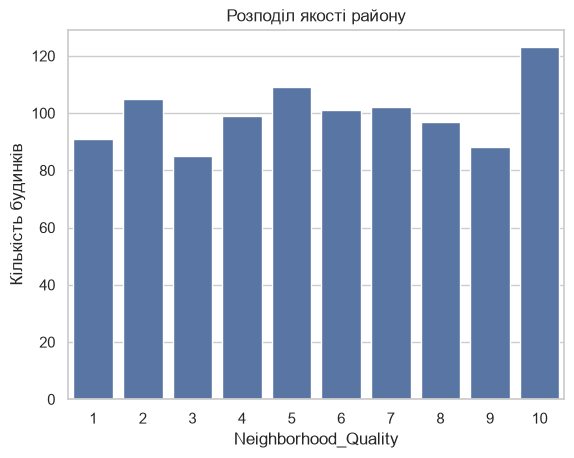

In [ ]:
sns.countplot(data=df, x="Neighborhood_Quality")
plt.title("Розподіл якості району")
plt.ylabel("Кількість будинків")
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [ ]:
df["Num_Bathrooms"].value_counts().sort_index()

Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64

### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

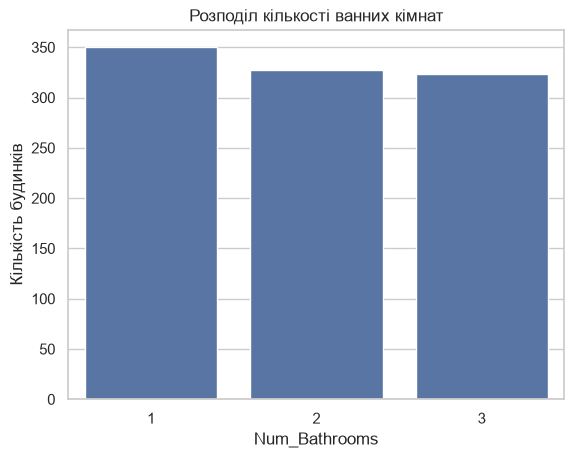

In [ ]:
sns.countplot(data=df, x="Num_Bathrooms")
plt.title("Розподіл кількості ванних кімнат")
plt.ylabel("Кількість будинків")
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

На попарних графіках ціна майже лінійно зростає зі збільшенням площі будинку. Зв’язок ціни з площею ділянки значно слабший.

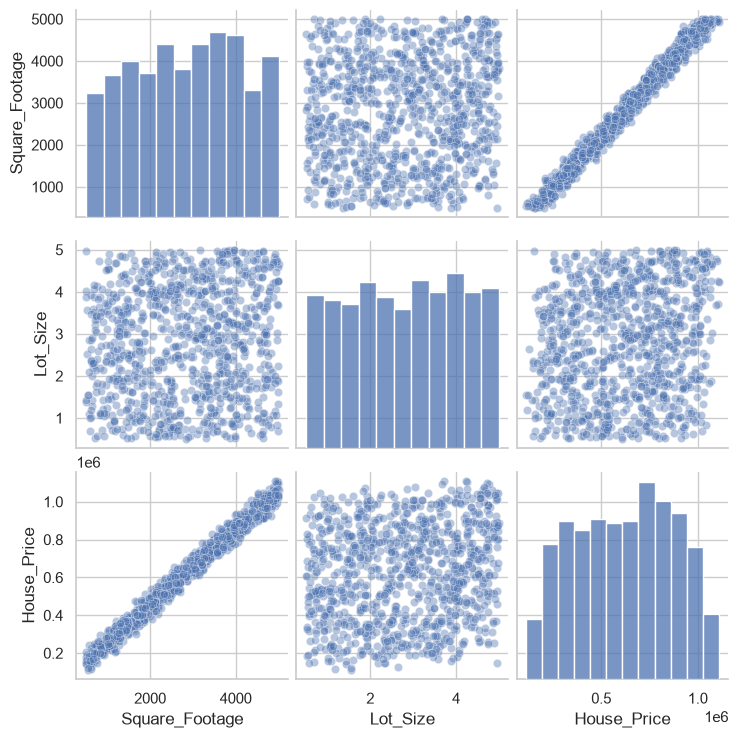

In [ ]:
# Попарні графіки ціни, площі будинку та площі ділянки.
sns.pairplot(df[["Square_Footage", "Lot_Size", "House_Price"]],
             diag_kind="hist", plot_kws={"alpha": 0.4})
plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

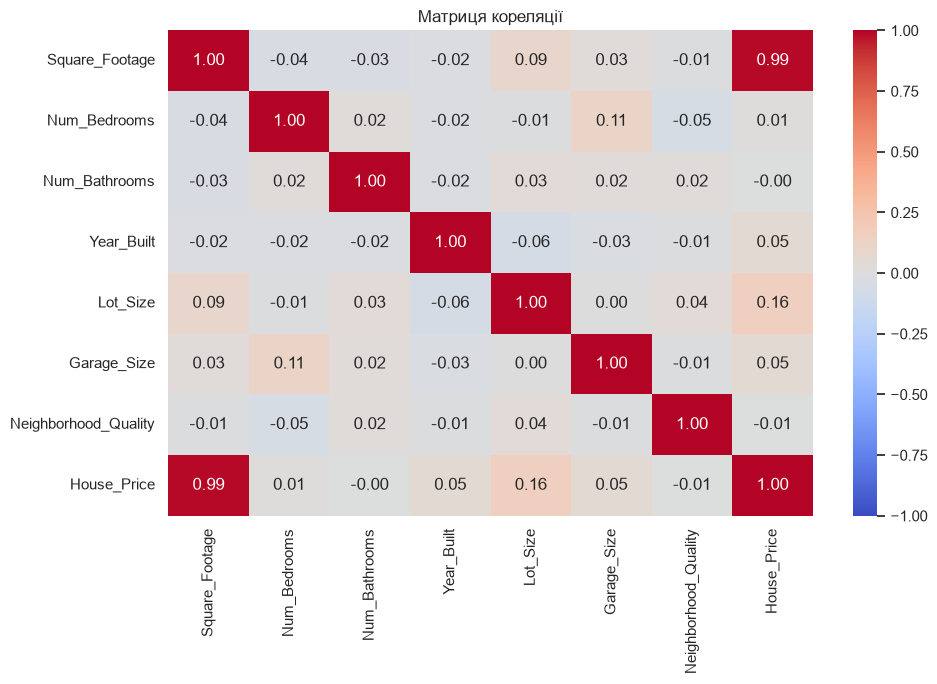

In [ ]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матриця кореляції")
plt.tight_layout()
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [ ]:
corr["House_Price"].drop("House_Price").sort_values(ascending=False)

Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64

## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [ ]:
X = df.drop(columns="House_Price")
y = df["House_Price"]

### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (800, 7)
Тестова вибірка: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [ ]:
models = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()),
                                   ("model", LinearRegression())]),
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
    "Lasso": Pipeline([("scaler", StandardScaler()), ("model", Lasso())]),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [ ]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Модель": name,
        "R²": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred)
    })

results_df = pd.DataFrame(results).set_index("Модель")
display(results_df.sort_values("R²", ascending=False))

,R²,MAE,MSE
Модель,,,
Linear Regression,0.998426,8174.583600,1.014348e+08
Lasso,0.998426,8174.748374,1.014366e+08
Ridge,0.998410,8241.586911,1.024810e+08
Gradient Boosting,0.996510,12305.217615,2.249656e+08
Random Forest,0.993879,16129.958024,3.945412e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

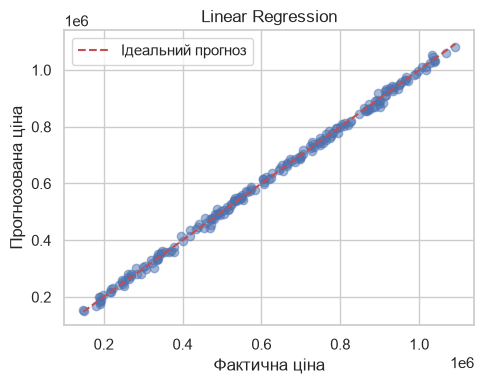

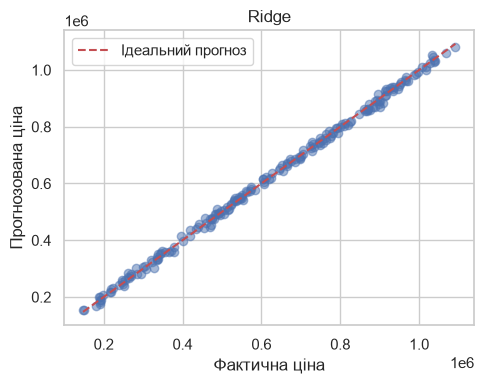

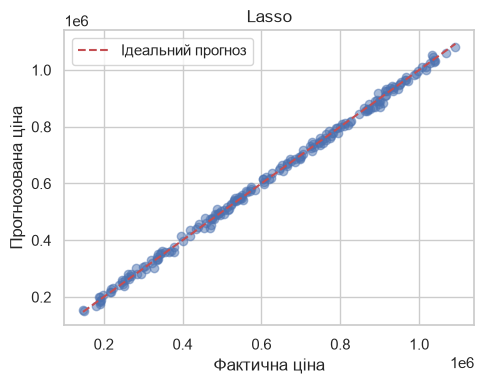

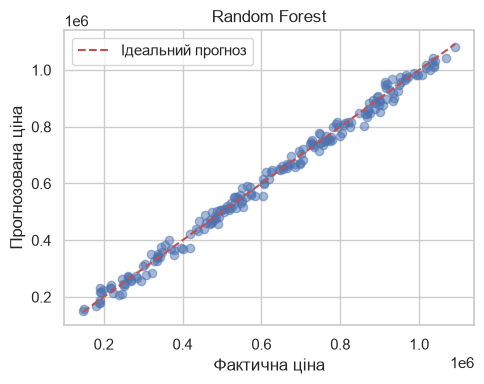

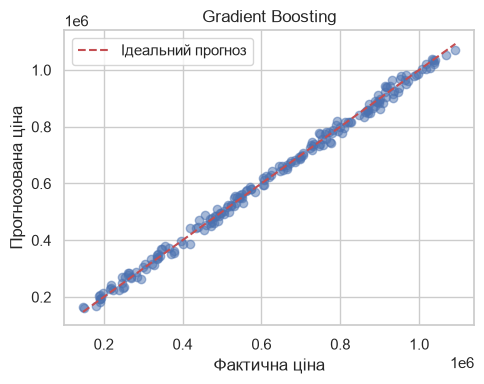

In [ ]:
for name, pred in predictions.items():
    plt.figure(figsize=(5, 4))
    plt.scatter(y_test, pred, alpha=0.5)
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    plt.plot([low, high], [low, high], "r--", label="Ідеальний прогноз")
    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(name)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [ ]:
param_grid = {
    "n_estimators": [50, 100],
    "max_features": [0.8, 1.0],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}

grid = GridSearchCV(RandomForestRegressor(random_state=42),
                    param_grid, cv=3, scoring="r2", n_jobs=1)
grid.fit(X_train, y_train)
print("Найкращі параметри:", grid.best_params_)
print("Середній R² на крос-валідації:", grid.best_score_)

Найкращі параметри: {'max_depth': 10, 'max_features': 0.8, 'min_samples_split': 2, 'n_estimators': 100}
Середній R² на крос-валідації: 0.9918839717947732


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [ ]:
best_rf = RandomForestRegressor(**grid.best_params_, random_state=42)
best_rf.fit(X_train, y_train)
best_pred = best_rf.predict(X_test)

optimized_metrics = {
    "R²": r2_score(y_test, best_pred),
    "MAE": mean_absolute_error(y_test, best_pred),
    "MSE": mean_squared_error(y_test, best_pred)
}
display(pd.Series(optimized_metrics, name="Random Forest після оптимізації"))

R²     9.941694e-01
MAE    1.555456e+04
MSE    3.758336e+08
Name: Random Forest після оптимізації, dtype: float64

### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [ ]:
comparison = pd.DataFrame([results_df.loc["Random Forest"].to_dict(), optimized_metrics], index=["Random Forest до оптимізації", "Random Forest після оптимізації"])
display(comparison)

,R²,MAE,MSE
Random Forest до оптимізації,0.993879,16129.958024,3.945412e+08
Random Forest після оптимізації,0.994169,15554.560129,3.758336e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Після підбору параметрів якість Random Forest трохи покращилася: R² зріс із 0.993879 до 0.994169, MAE зменшилася з 16129.96 до 15554.56, а MSE - з 394541219.25 до 375833614.99. Найкращі параметри: n_estimators=100, max_features=0.8, max_depth=10, min_samples_split=2

Серед двох варіантів Random Forest доцільно вибрати оптимізований, оскільки всі три тестові метрики кращі. Однак покращення невелике, а лінійна регресія на цьому датасеті дає точніші прогнози

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [ ]:
linear_pred = predictions["Linear Regression"]
prediction_table = pd.DataFrame({
    "Фактична ціна": y_test,
    "Прогнозована ціна": linear_pred
})
prediction_table["Похибка, %"] = (np.abs(y_test - linear_pred) / y_test.abs().replace(0, np.nan) * 100)
display(prediction_table.sample(10, random_state=42).round(2))

,Фактична ціна,Прогнозована ціна,"Похибка, %"
436,1068538.11,1059729.02,0.82
899,194353.74,187868.55,3.34
346,270230.64,279715.82,3.51
60,986006.86,981949.27,0.41
867,953339.73,957382.95,0.42
432,914555.75,909764.27,0.52
543,746167.73,742469.14,0.50
361,646766.29,654445.55,1.19
486,523323.07,524605.44,0.25
277,1008539.16,1011343.64,0.28


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

1. Побудовано Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting. Для лінійних моделей застосовано StandardScaler у Pipeline. Дані поділено на 800 навчальних і 200 тестових спостережень.
2. Найкращі значення всіх трьох метрик отримала Linear Regression: R² = 0.998426, MAE = 8174.58, MSE = 101434798.51. Lasso показала майже такий самий результат.
3. Підбір гіперпараметрів Random Forest трохи покращив усі метрики, але оптимізований ліс залишився менш точним за лінійну регресію.
4. На тестовій вибірці середня абсолютна похибка лінійної регресії становить приблизно 8175 одиниць ціни, а середня абсолютна відсоткова похибка - 1.66%. Отже, для цього датасету прогнози досить точні; така якість не гарантується на інших даних.
5. Найсильніше з ціною корелює площа будинку (приблизно 0.991). На якість прогнозу також можуть впливати розмір ділянки, кількість кімнат, рік побудови, гараж, місце розташування та стан будинку. Важливі повнота й достовірність даних, наявність викидів і відповідність навчальної вибірки новим об’єктам. У використаному датасеті пропусків і дублікатів немає.